# DSCI 552 — Homework 4
**Time-series Classification and ISLR 4.8.3 / 4.8.7**

**Name:** Wendu Liu  
**GitHub Username:** `wenduliu-ops`  
**USC ID:** 8752-8093-81

## 1. Time Series Classification Part 1 — reused from Homework 3

### (a) Obtain Data

**Imports and configuration**

In [3]:
from pathlib import Path
import re
import io
import zipfile
import warnings
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.special import expit
from sklearn.base import clone
from sklearn.exceptions import ConvergenceWarning
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, confusion_matrix, ConfusionMatrixDisplay,
                             roc_curve, roc_auc_score, RocCurveDisplay, classification_report)
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, MinMaxScaler, label_binarize
import statsmodels.api as sm

SEED = 552
ACTIVITIES = ('bending1', 'bending2', 'cycling', 'lying', 'sitting', 'standing', 'walking')
SENSORS = ('avg_rss12', 'var_rss12', 'avg_rss13', 'var_rss13', 'avg_rss23', 'var_rss23')
STAT_NAMES = ('min', 'max', 'mean', 'median', 'std', 'q1', 'q3')
plt.rcParams['figure.dpi'] = 95
pd.set_option('display.max_columns', 20)
print('Libraries loaded.')

Libraries loaded.


**Read every activity file from the ZIP without extracting it manually.** One supplied CSV has a missing timestamp, and some CSV rows end with an extra delimiter; the reader handles these consistently.

In [4]:
EXPECTED_TIMES = pd.Index(np.arange(0, 120000, 250), name='time')

def find_files():
    pattern = re.compile(r'(?:AReM/)?(' + '|'.join(ACTIVITIES) + r')/dataset(\d+)\.csv$')
    candidates = (Path('Homework 3, 4 Data.zip'), Path('AReM.zip'),
                  Path('data') / 'Homework 3, 4 Data.zip')
    for archive in candidates:
        if archive.exists():
            with zipfile.ZipFile(archive) as zf:
                files = []
                for name in zf.namelist():
                    match = pattern.fullmatch(name)
                    if match:
                        activity, num = match.group(1), int(match.group(2))
                        files.append((activity, num, zf.read(name)))
            if files:
                return sorted(files, key=lambda r: (ACTIVITIES.index(r[0]), r[1]))
    for parent in (Path('AReM'), Path('data') / 'AReM'):
        if parent.is_dir():
            files = []
            for activity in ACTIVITIES:
                for p in (parent / activity).glob('dataset*.csv'):
                    m = re.fullmatch(r'dataset(\d+)\.csv', p.name)
                    if m:
                        files.append((activity, int(m.group(1)), p.read_bytes()))
            if files:
                return sorted(files, key=lambda r: (ACTIVITIES.index(r[0]), r[1]))
    raise FileNotFoundError("Place 'Homework 3, 4 Data.zip' next to this notebook.")

def parse_csv(raw, filename):
    parsed = []
    for line in raw.decode('utf-8-sig').splitlines():
        line = line.strip()
        if not line or line.startswith('#'):
            continue
        parts = re.split(r'[,\s]+', line.rstrip(','))
        if len(parts) != 7:
            raise ValueError(f'Bad row in {filename}: {line!r}')
        parsed.append([float(x) for x in parts])
    df = pd.DataFrame(parsed, columns=['time', *SENSORS])
    df['time'] = df['time'].astype(int)
    df = df.set_index('time').sort_index()
    if df.index.duplicated().any() or not df.index.isin(EXPECTED_TIMES).all():
        raise ValueError(f'Bad timestamp(s) in {filename}')
    missing = len(EXPECTED_TIMES.difference(df.index))
    df = df.reindex(EXPECTED_TIMES).interpolate(method='index', limit_direction='both')
    assert df.shape == (480, 6) and np.isfinite(df.values).all()
    return df, missing

records = []
for activity, number, raw in find_files():
    name = f'{activity}/dataset{number}.csv'
    frame, missing = parse_csv(raw, name)
    split = 'test' if number <= (2 if activity.startswith('bending') else 3) else 'train'
    records.append(dict(name=name, activity=activity, number=number,
                        split=split, readings=frame, interpolated=missing))
assert len(records) == 88
print(f'Recordings: {len(records)}; repaired missing timestamps: {sum(r["interpolated"] for r in records)}')
display(pd.crosstab(pd.Series([r['activity'] for r in records], name='activity'),
                    pd.Series([r['split'] for r in records], name='split')))

Recordings: 88; repaired missing timestamps: 1


split,test,train
activity,,
bending1,2,5
bending2,2,4
cycling,3,12
lying,3,12
sitting,3,12
standing,3,12
walking,3,12


### (b) Training and test datasets
Per the assignment, `bending1` and `bending2` datasets 1–2 are test, and datasets 1–3 for every other activity are test. The remaining recordings are training data. **All feature selection and hyperparameter tuning will use training data only.**

In [5]:
train_records = [r for r in records if r['split'] == 'train']
test_records = [r for r in records if r['split'] == 'test']
assert len(train_records) == 69 and len(test_records) == 19
assert not (set(r['name'] for r in train_records) & set(r['name'] for r in test_records))
all_names = pd.Index([r['name'] for r in records], name='Instance')
train_idx = np.array([i for i, r in enumerate(records) if r['split'] == 'train'])
test_idx  = np.array([i for i, r in enumerate(records) if r['split'] == 'test'])
y_all = np.array([r['activity'] for r in records])
y_binary = np.array([1 if r['activity'].startswith('bending') else 0 for r in records])
y_train, y_test = y_binary[train_idx], y_binary[test_idx]
y_multi_train, y_multi_test = y_all[train_idx], y_all[test_idx]
print('Training:', len(train_idx), 'Testing:', len(test_idx))
print('Binary class counts (non-bending=0, bending=1):', Counter(y_train))

Training: 69 Testing: 19
Binary class counts (non-bending=0, bending=1): Counter({np.int64(0): 60, np.int64(1): 9})


### (c) Time-domain feature extraction
Use minimum, maximum, mean, median, standard deviation, first quartile and third quartile. Each recording has 6 sensor series, producing 42 features without time splitting. This is repeated here only to support HW4 Problem 2.

In [6]:
# A shape of (88 recordings, 480 time points, 6 sensors) keeps time order intact.
A = np.stack([r['readings'][list(SENSORS)].to_numpy() for r in records], axis=0)

def summary_stats(x):
    """Return (n_records, n_sensors, 7) time-domain statistics for a time segment."""
    return np.stack((np.min(x, axis=1), np.max(x, axis=1), np.mean(x, axis=1),
                     np.median(x, axis=1), np.std(x, axis=1, ddof=1),
                     np.percentile(x, 25, axis=1), np.percentile(x, 75, axis=1)), axis=-1)

def segmented_features(l):
    """Split EACH sensor's 480 ordered measurements into l nearly equal blocks."""
    assert isinstance(l, int) and 1 <= l <= 20
    pieces = np.array_split(A, l, axis=1)
    matrix = np.concatenate([summary_stats(piece).reshape(len(records), -1)
                             for piece in pieces], axis=1)
    columns = [f's{sensor}_part{j}_{stat}' for j in range(1, l + 1)
               for sensor in range(1, 7) for stat in STAT_NAMES]
    result = pd.DataFrame(matrix, index=all_names, columns=columns)
    assert result.shape == (88, 42*l) and np.isfinite(matrix).all()
    return result

feature_cache = {l: segmented_features(l) for l in range(1, 21)}
features_1 = feature_cache[1]
print('No-split features:', features_1.shape)
print('Split into 20 parts:', feature_cache[20].shape)
display(features_1.head(3).iloc[:, :14].round(3))

No-split features: (88, 42)
Split into 20 parts: (88, 840)


,s1_part1_min,s1_part1_max,s1_part1_mean,s1_part1_median,s1_part1_std,s1_part1_q1,s1_part1_q3,s2_part1_min,s2_part1_max,s2_part1_mean,s2_part1_median,s2_part1_std,s2_part1_q1,s2_part1_q3
Instance,,,,,,,,,,,,,,
bending1/dataset1.csv,37.25,45.00,40.625,40.50,1.477,39.25,42.00,0.0,1.30,0.359,0.43,0.323,0.0,0.5
bending1/dataset2.csv,38.00,45.67,42.813,42.50,1.436,42.00,43.67,0.0,1.22,0.372,0.47,0.289,0.0,0.5
bending1/dataset3.csv,35.00,47.40,43.954,44.33,1.559,43.00,45.00,0.0,1.70,0.426,0.47,0.339,0.0,0.5


## 2. Time Series Classification Part 2: Binary and Multiclass Classification
The class label is either **bending vs. other activities** for binary experiments or one of the **seven individual activities** for multiclass experiments. We use only training records for cross-validation. Predictions on the 19 test records are reserved for the final evaluation.

### (a) Binary Classification Using Logistic Regression

#### (a)i. Three-feature scatter plots
Following HW3 part 1(c)iv, we use **minimum, mean, maximum** for consistency. Each chart uses one of sensor series **1, 2 and 6**, with color marking bending versus all other activities. These are descriptive plots, not fitted classifiers.

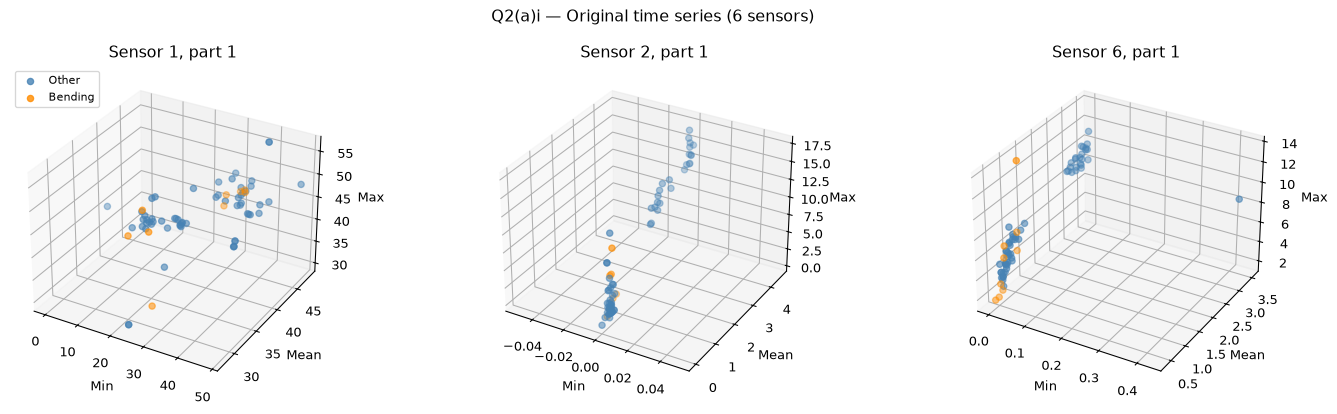

In [7]:
SELECTED_STATS = ('min', 'mean', 'max')  # Use the same set as HW3 1(c)iv.

def plot_three_features(l, suptitle):
    fig = plt.figure(figsize=(15, 4.4 if l == 1 else 8.0))
    panels = [(sensor, part) for part in range(1, l + 1) for sensor in (1, 2, 6)]
    for i, (sensor, part) in enumerate(panels, 1):
        ax = fig.add_subplot(l, 3, i, projection='3d')
        X = feature_cache[l].iloc[train_idx]
        xx = X[f's{sensor}_part{part}_min'].to_numpy()
        yy = X[f's{sensor}_part{part}_mean'].to_numpy()
        zz = X[f's{sensor}_part{part}_max'].to_numpy()
        for val, name, color in ((0, 'Other', 'steelblue'), (1, 'Bending', 'darkorange')):
            mask = y_train == val
            ax.scatter(xx[mask], yy[mask], zz[mask], label=name, alpha=.8,
                       s=22, color=color)
        ax.set(xlabel='Min', ylabel='Mean', zlabel='Max',
               title=f'Sensor {sensor}, part {part}')
        if i == 1:
            ax.legend(fontsize=8, loc='upper left')
    fig.suptitle(suptitle)
    plt.tight_layout()
    plt.show()

plot_three_features(1, 'Q2(a)i — Original time series (6 sensors)')

#### (a)ii. Split each time series in two and plot again
Each of the 6 sensors is divided into two consecutive parts of about 240 observations. This gives **12 sensor segments per recording**, while the number of recordings is unchanged.

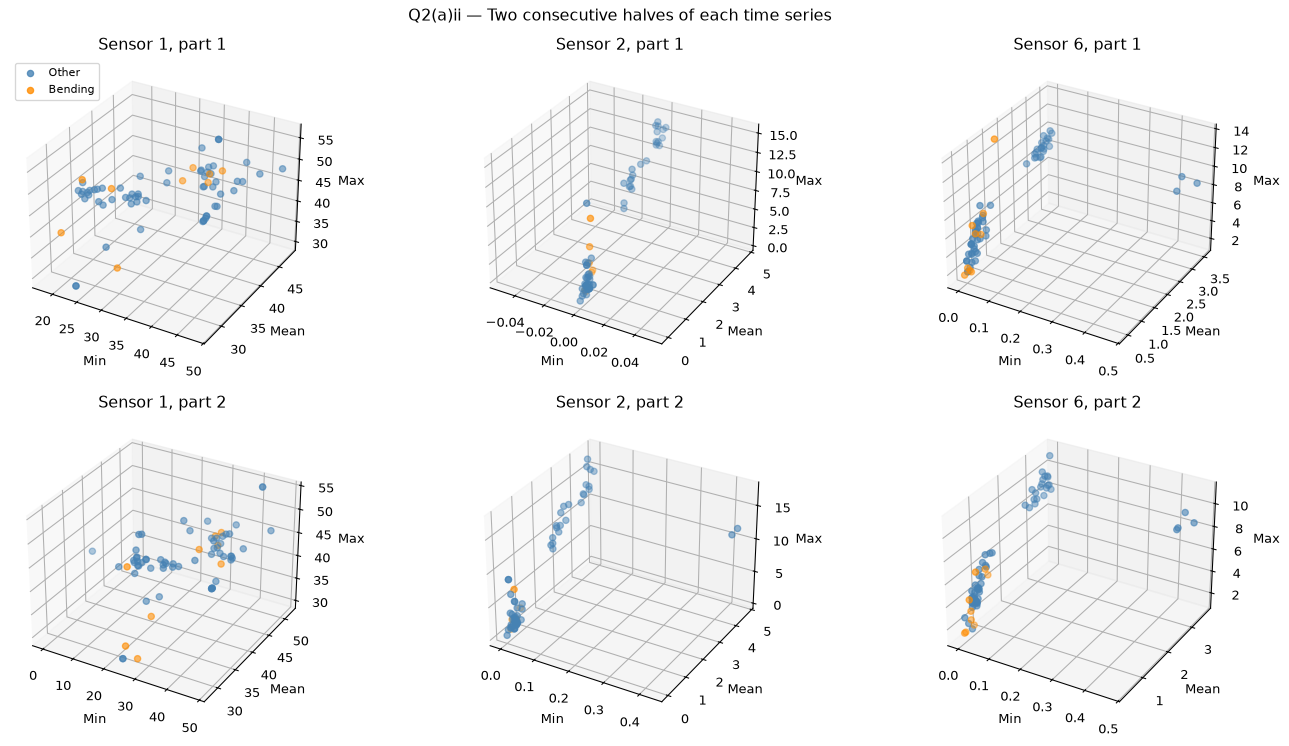

Comparison: two-piece plots reveal within-recording changes that are hidden by a single full-series summary.


In [8]:
plot_three_features(2, 'Q2(a)ii — Two consecutive halves of each time series')
print('Comparison: two-piece plots reveal within-recording changes that are hidden by a single full-series summary.')

#### (a)iii. Select the number of segments $l$ and the number of features $p$ using 5-fold CV

For each $l\in\{1,\ldots,20\}$, each recording yields $42l$ features. We evaluate logistic regression with recursive feature elimination (RFE) and $p\in\{5,10,20\}$ selected features. We use five **stratified** folds because bending is rare (9/69 in training). The pipeline contains scaling and RFE, so **each CV fold fits its own scaler and selected features using only that fold's training partition**. This is the *right* approach. The wrong approach is to standardize and/or select features on all 69 observations first and then cross-validate; this leaks validation information and makes estimates optimistic.

The choice of $p$ uses a small, specified grid for practical computation; this is a grid search, not an exhaustive search of every integer $p$. We use a large inverse penalty $C$ to approximate the assignment's unregularized logistic regression. In (b) we explicitly tune an L1 penalty instead.

Best (l,p): (1, 5) | 5-fold mean accuracy: 0.9714


,l,p,cv_accuracy,cv_std
0,1,5,0.9714,0.0391
1,3,5,0.9571,0.0391
2,1,10,0.9571,0.0639
3,8,10,0.9571,0.0639
4,11,20,0.9571,0.0639
5,19,20,0.9571,0.0639
6,2,5,0.9429,0.0598
7,11,5,0.9429,0.0319
8,18,5,0.9429,0.0598
9,2,10,0.9429,0.0598


Selected features: ['s1_part1_q3', 's2_part1_max', 's4_part1_max', 's5_part1_min', 's5_part1_max']


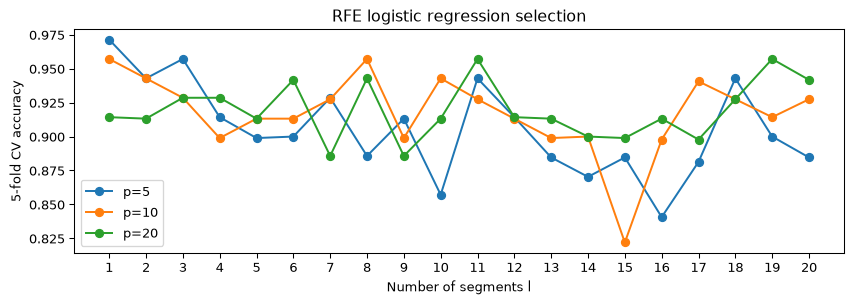

In [9]:
folds_binary = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
P_GRID = (5, 10, 20)

def make_rfe_model(p):
    linear = LogisticRegression(solver='liblinear', C=1e5, max_iter=500,
                                random_state=SEED)
    return Pipeline([('scale', StandardScaler()),
                     ('rfe', RFE(estimator=clone(linear), n_features_to_select=p,
                                 step=0.5)),
                     ('model', clone(linear))])

results_rfe = []
with warnings.catch_warnings():
    warnings.filterwarnings('ignore', category=ConvergenceWarning)
    for l in range(1, 21):
        X = feature_cache[l].iloc[train_idx]
        for p in P_GRID:
            score = cross_val_score(make_rfe_model(p), X, y_train,
                                    cv=folds_binary, scoring='accuracy', n_jobs=1)
            results_rfe.append({'l':l, 'p':p, 'cv_accuracy':score.mean(),
                                'cv_std':score.std(ddof=1)})
rfe_cv = pd.DataFrame(results_rfe).sort_values(
    ['cv_accuracy', 'p', 'l'], ascending=[False, True, True]).reset_index(drop=True)
best_l, best_p = int(rfe_cv.iloc[0]['l']), int(rfe_cv.iloc[0]['p'])
X_best_train = feature_cache[best_l].iloc[train_idx]
X_best_test = feature_cache[best_l].iloc[test_idx]
selected_rfe = make_rfe_model(best_p)
with warnings.catch_warnings():
    warnings.filterwarnings('ignore', category=ConvergenceWarning)
    selected_rfe.fit(X_best_train, y_train)
selected_names = X_best_train.columns[selected_rfe.named_steps['rfe'].support_]
print('Best (l,p):', (best_l,best_p), '| 5-fold mean accuracy:', round(rfe_cv.iloc[0].cv_accuracy, 4))
display(rfe_cv.head(12).round(4))
print('Selected features:', selected_names.tolist())
fig, ax = plt.subplots(figsize=(9, 3.3))
for p, part in rfe_cv.groupby('p'):
    ax.plot(part.sort_values('l')['l'], part.sort_values('l')['cv_accuracy'], marker='o', label=f'p={p}')
ax.set(xlabel='Number of segments l', ylabel='5-fold CV accuracy', title='RFE logistic regression selection')
ax.set_xticks(range(1,21)); ax.legend(); plt.tight_layout(); plt.show()

#### (a)iv. Training confusion matrix, ROC/AUC, coefficients and p-values
For the RFE-selected logistic regression we report the complete training prediction confusion matrix and ROC/AUC. We also fit an **unpenalized statsmodels GLM** using the *same selected features* to obtain approximate Wald p-values. **Caution:** if the classes are nearly perfectly separated, fitted coefficients and Wald p-values become unstable or meaningless. These must not be interpreted as reliable significance tests in that case.

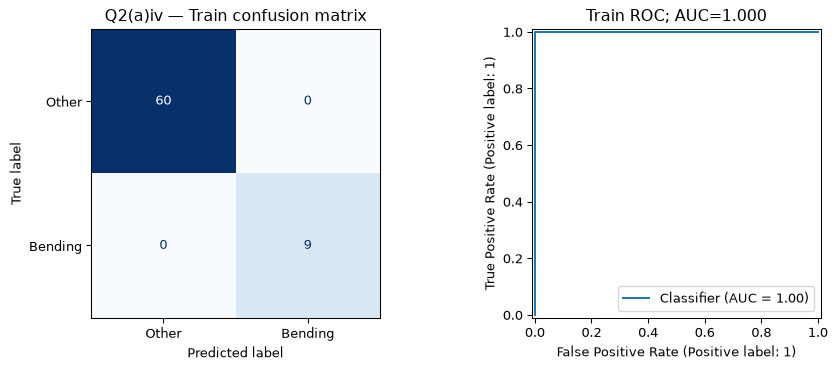

RFE train accuracy=1.0000; AUC=1.0000
CAUTION: apparent separation/instability; GLM Wald p-values may be invalid.


,feature,sklearn_coefficient,GLM_coefficient,GLM_Wald_p
0,Intercept,-23.2540,-63.6450,0.9988
1,s1_part1_q3,-8.4605,-25.6606,0.9994
2,s2_part1_max,-6.7153,-22.8348,0.9997
3,s4_part1_max,1.3182,4.8783,0.9999
4,s5_part1_min,11.5323,32.6016,0.9991
5,s5_part1_max,13.0032,33.3201,0.9992


In [10]:
train_prob_rfe = selected_rfe.predict_proba(X_best_train)[:, 1]
train_pred_rfe = selected_rfe.predict(X_best_train)
train_acc_rfe = accuracy_score(y_train, train_pred_rfe)
train_auc_rfe = roc_auc_score(y_train, train_prob_rfe)
fig, axs = plt.subplots(1, 2, figsize=(10, 4))
ConfusionMatrixDisplay.from_predictions(y_train, train_pred_rfe, display_labels=['Other','Bending'],
                                        ax=axs[0], cmap='Blues', colorbar=False)
axs[0].set_title('Q2(a)iv — Train confusion matrix')
RocCurveDisplay.from_predictions(y_train, train_prob_rfe, ax=axs[1])
axs[1].set_title(f'Train ROC; AUC={train_auc_rfe:.3f}')
plt.tight_layout(); plt.show()
print(f'RFE train accuracy={train_acc_rfe:.4f}; AUC={train_auc_rfe:.4f}')

# Prediction model coefficients on the selected standardized features.
coef_rfe = pd.DataFrame({'feature':['Intercept', *selected_names.tolist()],
                         'sklearn_coefficient': np.r_[selected_rfe.named_steps['model'].intercept_,
                                     selected_rfe.named_steps['model'].coef_.ravel()]})
# A GLM fit on the same selected standardized columns gives conventional Wald p-values,
# but ordinary Wald inference is not dependable under quasi/perfect separation.
Z = selected_rfe.named_steps['scale'].transform(X_best_train)
Z = Z[:, selected_rfe.named_steps['rfe'].support_]
try:
    with warnings.catch_warnings(record=True) as glm_warnings:
        warnings.simplefilter('always')
        glm = sm.GLM(y_train, sm.add_constant(Z, has_constant='add'),
                     family=sm.families.Binomial()).fit(maxiter=200, disp=False)
    coef_rfe['GLM_coefficient'] = glm.params
    coef_rfe['GLM_Wald_p'] = glm.pvalues
    suspicious = (any('separat' in str(w.message).lower() for w in glm_warnings)
                  or not np.isfinite(glm.params).all()
                  or np.max(np.abs(glm.params)) > 25)
    if suspicious:
        print('CAUTION: apparent separation/instability; GLM Wald p-values may be invalid.')
except (ValueError, np.linalg.LinAlgError, OverflowError) as ex:
    coef_rfe['GLM_coefficient'] = np.nan
    coef_rfe['GLM_Wald_p'] = np.nan
    print('Unpenalized GLM p-values unavailable due to instability:', repr(ex))
display(coef_rfe.round(4))

#### (a)v. Evaluate on reserved test data
The test set is split into **exactly the same number $l$ of segments** as the training set. All preprocessing and feature selection come from training only. The comparison is between the test accuracy and the 5-fold CV accuracy.

In [11]:
test_pred_rfe = selected_rfe.predict(X_best_test)
test_prob_rfe = selected_rfe.predict_proba(X_best_test)[:,1]
test_acc_rfe = accuracy_score(y_test, test_pred_rfe)
print(f'Test accuracy: {test_acc_rfe:.4f}; CV accuracy: {rfe_cv.iloc[0].cv_accuracy:.4f}')
print('Test ROC AUC:', round(roc_auc_score(y_test, test_prob_rfe), 4))
display(pd.DataFrame(confusion_matrix(y_test, test_pred_rfe),
                     index=['True other','True bending'], columns=['Pred other','Pred bending']))

Test accuracy: 1.0000; CV accuracy: 0.9714
Test ROC AUC: 1.0


,Pred other,Pred bending
True other,15,0
True bending,0,4


#### (a)vi. Linear separation / model stability

**Assessment:** The data may exhibit (quasi-)linear separation: a strong training fit on such a small, imbalanced sample can produce large logistic regression coefficients and unstable Wald p-values. Compare the training and testing scores above; interpret coefficient magnitude or nominal p-values cautiously rather than treating them as definitive evidence. In particular, if the model classifies the training observations perfectly, perfect separation is a concern. Penalization and limiting the maximum number of iterations can improve numerical stability.

#### (a)vii. Class imbalance and case-control correction
There are only 9 bending recordings among 69 training samples. We illustrate balanced **case-control oversampling** of bending examples, fit a logistic model on that balanced sample, and adjust the fitted intercept by $\log(\pi/(1-\pi))-\log(q/(1-q))$, where $\pi$ is the true training prevalence and $q$ is the oversampled prevalence. The class balance changes the fitted intercept; the correction restores the original prior odds approximately. A moderate L2 penalty is used here for numerical stability. We report training confusion matrix, ROC, AUC, and test metrics.

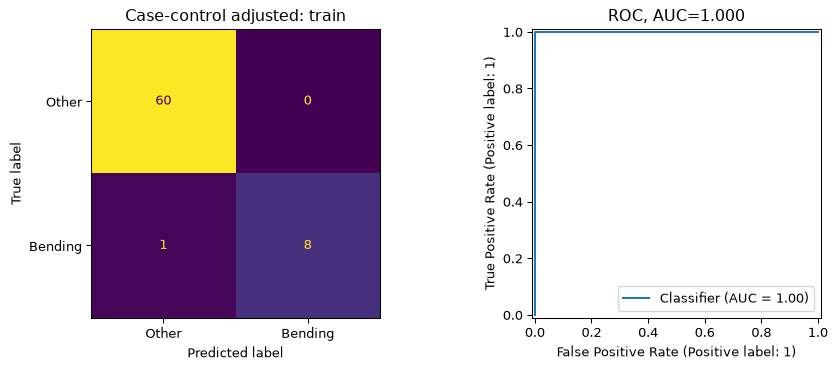

Original / oversampled prevalence: 0.13 / 0.5
Intercept adjustment: -1.897
Train accuracy: 0.9855
Test accuracy: 1.0
Test AUC: 1.0


In [12]:
rng = np.random.default_rng(SEED)
pos, neg = np.flatnonzero(y_train == 1), np.flatnonzero(y_train == 0)
resampled_indices = np.r_[neg, rng.choice(pos, size=len(neg), replace=True)]
q = np.mean(y_train[resampled_indices])   # sampling prevalence ~0.5
pi = np.mean(y_train)                     # original training prevalence
case_model = Pipeline([('scale', StandardScaler()),
                       ('model', LogisticRegression(C=1.0, solver='liblinear', max_iter=1000,
                                                    random_state=SEED))])
# Work with RFE-selected features; this avoids fitting the full 42*l high-dimensional vector.
X_case_train = X_best_train[selected_names]
X_case_test = X_best_test[selected_names]
case_model.fit(X_case_train.iloc[resampled_indices], y_train[resampled_indices])
shift = np.log(pi/(1-pi)) - np.log(q/(1-q))

def adjusted_case_probability(X):
    raw_log_odds = case_model.decision_function(X)
    return expit(raw_log_odds + shift)

case_train_prob = adjusted_case_probability(X_case_train)
case_train_pred = (case_train_prob >= 0.5).astype(int)
case_test_prob = adjusted_case_probability(X_case_test)
case_test_pred = (case_test_prob >= 0.5).astype(int)
fig, ax = plt.subplots(1,2,figsize=(10,4))
ConfusionMatrixDisplay.from_predictions(y_train, case_train_pred,
                                        display_labels=['Other','Bending'], ax=ax[0], colorbar=False)
ax[0].set_title('Case-control adjusted: train')
RocCurveDisplay.from_predictions(y_train, case_train_prob, ax=ax[1])
ax[1].set_title(f'ROC, AUC={roc_auc_score(y_train, case_train_prob):.3f}')
plt.tight_layout(); plt.show()
print('Original / oversampled prevalence:', round(pi, 3), '/', round(q, 3))
print('Intercept adjustment:', round(shift, 3))
print('Train accuracy:', round(accuracy_score(y_train,case_train_pred),4))
print('Test accuracy:', round(accuracy_score(y_test,case_test_pred),4))
print('Test AUC:', round(roc_auc_score(y_test,case_test_prob),4))

### (b) Binary classification with L1-penalized logistic regression
Unlike (a), this experiment explicitly uses **L1 regularization for feature selection**. Tune both the number of segments $l$ and inverse penalty $C$ using the same stratified five-fold training-only CV. As in (a), scaling happens inside each fold.

#### (b)i. Tune $(l,C)$ jointly using 5-fold stratified CV

In [13]:
C_GRID = (0.01, 0.1, 1.0, 10.0)

def make_l1_binary(C):
    return Pipeline([('scale', StandardScaler()),
                     ('model', LogisticRegression(l1_ratio=1.0, solver='liblinear', C=C,
                                                    max_iter=1200, random_state=SEED))])

results_l1 = []
with warnings.catch_warnings():
    warnings.filterwarnings('ignore', category=ConvergenceWarning)
    for l in range(1,21):
        X = feature_cache[l].iloc[train_idx]
        for C in C_GRID:
            cvscores = cross_val_score(make_l1_binary(C), X, y_train, cv=folds_binary,
                                       scoring='accuracy', n_jobs=1)
            results_l1.append(dict(l=l,C=C,cv_accuracy=cvscores.mean(),cv_std=cvscores.std(ddof=1)))
l1_cv = pd.DataFrame(results_l1).sort_values(
    ['cv_accuracy','l','C'], ascending=[False,True,True]).reset_index(drop=True)
l1_l, l1_C = int(l1_cv.iloc[0].l), float(l1_cv.iloc[0].C)
l1_bin = make_l1_binary(l1_C)
l1_bin.fit(feature_cache[l1_l].iloc[train_idx], y_train)
l1_bin_pred = l1_bin.predict(feature_cache[l1_l].iloc[test_idx])
l1_bin_prob = l1_bin.predict_proba(feature_cache[l1_l].iloc[test_idx])[:,1]
print('Best L1 binary (l,C):', (l1_l, l1_C))
print('5-fold CV accuracy:', round(l1_cv.iloc[0].cv_accuracy, 4))
print('Test accuracy:', round(accuracy_score(y_test,l1_bin_pred),4))
print('Test AUC:', round(roc_auc_score(y_test,l1_bin_prob),4))
print('Number of nonzero coefficients:', np.count_nonzero(l1_bin.named_steps['model'].coef_))
display(l1_cv.head(10).round(4))

Best L1 binary (l,C): (11, 1.0)
5-fold CV accuracy: 0.9857
Test accuracy: 0.9474
Test AUC: 1.0
Number of nonzero coefficients: 8


,l,C,cv_accuracy,cv_std
0,11,1.0,0.9857,0.0319
1,11,10.0,0.9857,0.0319
2,12,1.0,0.9857,0.0319
3,12,10.0,0.9857,0.0319
4,18,10.0,0.9857,0.0319
5,1,1.0,0.9714,0.0391
6,13,1.0,0.9714,0.0391
7,18,1.0,0.9714,0.0391
8,19,1.0,0.9714,0.0391
9,19,10.0,0.9714,0.0391


#### (b)ii. Compare p-value/backward feature selection versus L1 penalization

We compare the test scores of the backward-selection (RFE) model and L1 regularization. The results below are computed from the fitted models above. RFE imposes a chosen number of features and can be computationally expensive; **L1 tends to be easier to implement** because the penalized model automatically shrinks some coefficients to zero. Neither model is guaranteed to win on a small held-out test set. Cross-validation is used for model selection, while the reserved test set measures final performance.

In [14]:
compare_binary = pd.DataFrame([
    {'Method':'RFE + logistic', 'l':best_l, 'CV accuracy':rfe_cv.iloc[0].cv_accuracy,
     'Test accuracy':test_acc_rfe, 'Test AUC':roc_auc_score(y_test,test_prob_rfe)},
    {'Method':'L1 logistic', 'l':l1_l, 'CV accuracy':l1_cv.iloc[0].cv_accuracy,
     'Test accuracy':accuracy_score(y_test,l1_bin_pred),
     'Test AUC':roc_auc_score(y_test,l1_bin_prob)}])
display(compare_binary.round(4))
if compare_binary.iloc[0]['Test accuracy'] > compare_binary.iloc[1]['Test accuracy']:
    print('Higher binary test accuracy: RFE + logistic.')
elif compare_binary.iloc[0]['Test accuracy'] < compare_binary.iloc[1]['Test accuracy']:
    print('Higher binary test accuracy: L1 logistic.')
else:
    print('Both binary methods have equal test accuracy.')

,Method,l,CV accuracy,Test accuracy,Test AUC
0,RFE + logistic,1,0.9714,1.0000,1.0
1,L1 logistic,11,0.9857,0.9474,1.0


Higher binary test accuracy: RFE + logistic.


### (c) Multiclass classification — seven activities
We now predict all seven activity classes. The rarest training class has only four examples, so five-fold stratified CV is not possible with every class present in each validation fold. We therefore use **four stratified folds** for multiclass hyperparameter selection. To compare methods fairly, every candidate is validated on the same folds; test data is never used for tuning.

#### (c)i. L1 multinomial logistic regression
Select the number of segments $l$ and the penalty $C$ by stratified CV. The `saga` solver supports **multinomial L1** optimization. A relaxed tolerance and capped iteration count are used to make the $l=1$ to $20$ search feasible. Report test error, confusion matrix, and one-vs-rest ROC curves for the seven classes.

Best multinomial L1 (l,C): (1, 3.0)
Multiclass 4-fold CV accuracy: 0.9134
Test error: 0.1053 | Test accuracy: 0.8947


,l,C,cv_accuracy,cv_std
0,1,3.0,0.9134,0.0322
1,2,3.0,0.8987,0.0558
2,3,3.0,0.8693,0.0307
3,4,3.0,0.8546,0.0768
4,5,3.0,0.8538,0.0605
5,14,3.0,0.8399,0.0581
6,2,0.3,0.8276,0.0755
7,18,3.0,0.8268,0.0429
8,16,0.3,0.8268,0.0429
9,10,0.3,0.8260,0.0962


              precision    recall  f1-score   support

    bending1       1.00      1.00      1.00         2
    bending2       1.00      1.00      1.00         2
     cycling       1.00      1.00      1.00         3
       lying       0.75      1.00      0.86         3
     sitting       1.00      0.67      0.80         3
    standing       0.67      0.67      0.67         3
     walking       1.00      1.00      1.00         3

    accuracy                           0.89        19
   macro avg       0.92      0.90      0.90        19
weighted avg       0.91      0.89      0.89        19



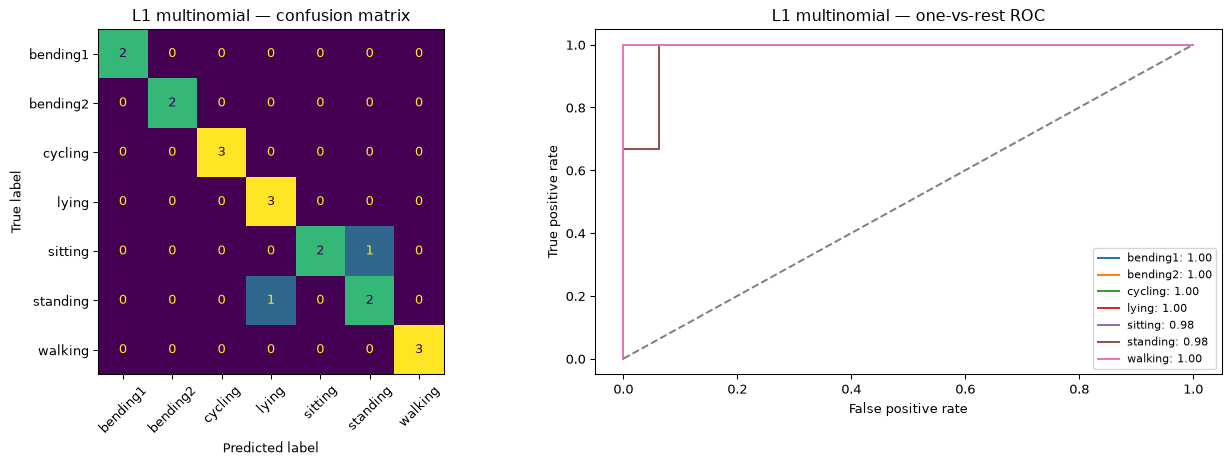

In [15]:
cv_multi = StratifiedKFold(n_splits=4, shuffle=True, random_state=SEED)
MULTI_C = (0.03, 0.3, 3.0)

def make_l1_multi(C):
    # In scikit-learn >=1.8, multiclass logistic uses a multinomial loss automatically.
    return Pipeline([('scale', StandardScaler()),
                     ('model', LogisticRegression(l1_ratio=1.0, solver='saga', C=C,
                        tol=5e-3, max_iter=450, random_state=SEED))])

results_multi = []
with warnings.catch_warnings():
    warnings.filterwarnings('ignore', category=ConvergenceWarning)
    for l in range(1, 21):
        X = feature_cache[l].iloc[train_idx]
        for C in MULTI_C:
            vals = cross_val_score(make_l1_multi(C), X, y_multi_train,
                                   cv=cv_multi, scoring='accuracy', n_jobs=1)
            results_multi.append(dict(l=l,C=C,cv_accuracy=vals.mean(),cv_std=vals.std(ddof=1)))
multi_cv = pd.DataFrame(results_multi).sort_values(
    ['cv_accuracy','l','C'], ascending=[False,True,True]).reset_index(drop=True)
multi_l, multi_C = int(multi_cv.iloc[0].l), float(multi_cv.iloc[0].C)
multinomial = make_l1_multi(multi_C)
with warnings.catch_warnings():
    warnings.filterwarnings('ignore', category=ConvergenceWarning)
    multinomial.fit(feature_cache[multi_l].iloc[train_idx], y_multi_train)
pred_multi = multinomial.predict(feature_cache[multi_l].iloc[test_idx])
prob_multi = multinomial.predict_proba(feature_cache[multi_l].iloc[test_idx])
acc_multi = accuracy_score(y_multi_test, pred_multi)
print('Best multinomial L1 (l,C):', (multi_l,multi_C))
print('Multiclass 4-fold CV accuracy:',round(multi_cv.iloc[0].cv_accuracy, 4))
print('Test error:',round(1-acc_multi,4), '| Test accuracy:', round(acc_multi, 4))
display(multi_cv.head(12).round(4))
print(classification_report(y_multi_test,pred_multi,labels=list(ACTIVITIES),zero_division=0))

def show_multiclass_eval(y_true, predictions, probabilities, classes, title):
    fig, ax = plt.subplots(1, 2, figsize=(14, 5))
    ConfusionMatrixDisplay.from_predictions(y_true, predictions, labels=classes,
                                            xticks_rotation=45, ax=ax[0], colorbar=False)
    ax[0].set_title(title + ' — confusion matrix')
    # One-vs-rest ROC: each class is positive against all the other classes.
    for i, cls in enumerate(classes):
        truth = (np.asarray(y_true) == cls).astype(int)
        if len(np.unique(truth)) != 2:
            continue
        fpr, tpr, _ = roc_curve(truth, probabilities[:,i])
        auc = roc_auc_score(truth, probabilities[:,i])
        ax[1].plot(fpr,tpr,label=f'{cls}: {auc:.2f}')
    ax[1].plot([0,1],[0,1],'--',color='gray')
    ax[1].set(xlabel='False positive rate',ylabel='True positive rate',
              title=title+' — one-vs-rest ROC')
    ax[1].legend(fontsize=8, loc='lower right')
    plt.tight_layout(); plt.show()

show_multiclass_eval(y_multi_test, pred_multi, prob_multi,
                     multinomial.named_steps['model'].classes_, 'L1 multinomial')

#### (c)ii. Gaussian Naive Bayes and Multinomial Naive Bayes
Tune $l=1,\dots,20$ using four-fold stratified CV. Gaussian NB models continuous features as normally distributed within each class. Multinomial NB requires **nonnegative input**; we use `MinMaxScaler` fitted inside each CV fold. This lets it run on the time-domain descriptors, although such measurements are not actual multinomial counts, so its probability assumptions are imperfect.

GaussianNB  best l: 1 test error: 0.1053


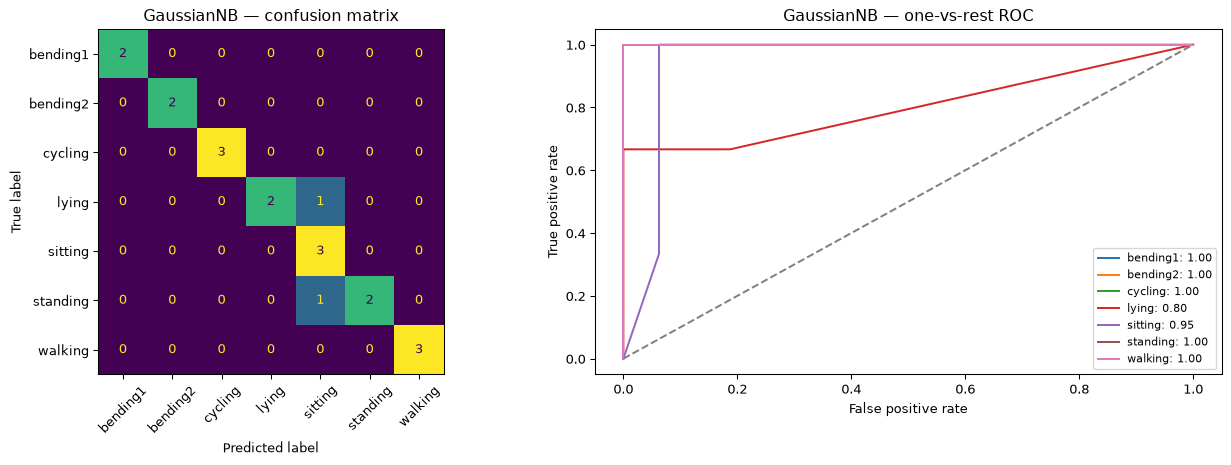

MultinomialNB  best l: 1 test error: 0.2105


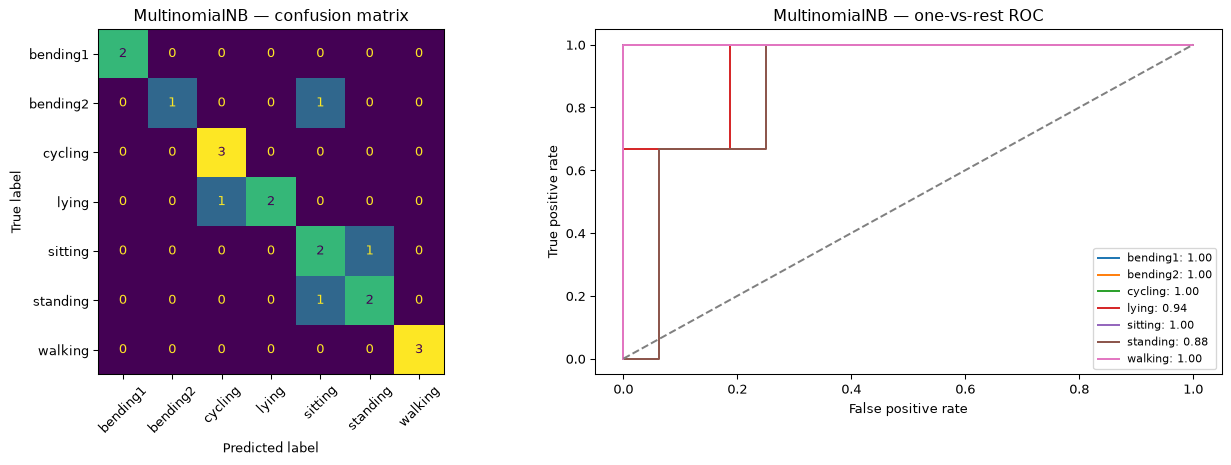

,Method,l,CV accuracy,Test accuracy,Test error
0,GaussianNB,1,0.8701,0.8947,0.1053
1,MultinomialNB,1,0.7827,0.7895,0.2105


In [16]:
nb_candidates = {
    'GaussianNB': Pipeline([('scale', StandardScaler()),('model', GaussianNB())]),
    'MultinomialNB': Pipeline([('scale', MinMaxScaler()),('model', MultinomialNB(alpha=1.0))])
}
nb_cv_rows=[]
for method, estimator in nb_candidates.items():
    for l in range(1,21):
        cv_values = cross_val_score(estimator, feature_cache[l].iloc[train_idx],
                                    y_multi_train, cv=cv_multi, scoring='accuracy')
        nb_cv_rows.append({'method':method,'l':l,'cv_accuracy':cv_values.mean()})
nb_cv = pd.DataFrame(nb_cv_rows)
nb_estimators={}
nb_evaluation=[]
for method, estimator in nb_candidates.items():
    sub=nb_cv[nb_cv.method==method].sort_values(['cv_accuracy','l'],ascending=[False,True])
    best_nb_l = int(sub.iloc[0].l)
    fit = clone(estimator).fit(feature_cache[best_nb_l].iloc[train_idx],y_multi_train)
    preds=fit.predict(feature_cache[best_nb_l].iloc[test_idx])
    probs=fit.predict_proba(feature_cache[best_nb_l].iloc[test_idx])
    accuracy=accuracy_score(y_multi_test,preds)
    nb_estimators[method]=(fit,best_nb_l)
    nb_evaluation.append({'Method':method,'l':best_nb_l,'CV accuracy':sub.iloc[0].cv_accuracy,
                          'Test accuracy':accuracy,'Test error':1-accuracy})
    print(method,' best l:',best_nb_l,'test error:',round(1-accuracy,4))
    show_multiclass_eval(y_multi_test,preds,probs,fit.named_steps['model'].classes_,method)
display(pd.DataFrame(nb_evaluation).round(4))

#### (c)iii. Which model performs best?

**Comparison principle:** Choose on the basis of held-out test error, and use cross-validation when deciding hyperparameters. Small test-set differences (19 observations) can be noisy. A Gaussian model can represent continuous sensor descriptors better than a Multinomial NB model; L1 multinomial logistic regression is a discriminative alternative that can capture interactions through many engineered features.

In [17]:
comparison_multi = pd.DataFrame([{'Method':'L1 multinomial logistic', 'l':multi_l,
                                  'CV accuracy':multi_cv.iloc[0].cv_accuracy,
                                  'Test accuracy':acc_multi, 'Test error':1-acc_multi},
                                  *nb_evaluation]).sort_values(['Test error','CV accuracy'],
                                                               ascending=[True,False]).reset_index(drop=True)
display(comparison_multi.round(4))
lowest = comparison_multi['Test error'].min()
winners = comparison_multi.loc[np.isclose(comparison_multi['Test error'], lowest), 'Method'].tolist()
print('Best observed test error:', round(lowest,4))
print('Method(s) tied for best test error:', ', '.join(winners))

,Method,l,CV accuracy,Test accuracy,Test error
0,L1 multinomial logistic,1,0.9134,0.8947,0.1053
1,GaussianNB,1,0.8701,0.8947,0.1053
2,MultinomialNB,1,0.7827,0.7895,0.2105


Best observed test error: 0.1053
Method(s) tied for best test error: L1 multinomial logistic, GaussianNB


## 3. ISLR 4.8.3 — QDA Bayes decision boundary

### Solution

Suppose there are $K$ classes and $X \mid Y=k \sim N(\mu_k,\sigma_k^2)$, with prior probability $\pi_k=P(Y=k)$. The class-conditional density is

$$
f_k(x)=\frac{1}{\sqrt{2\pi}\sigma_k}\exp\left[-\frac{(x-\mu_k)^2}{2\sigma_k^2}\right].
$$

By Bayes' theorem,

$$
P(Y=k\mid X=x)=\frac{\pi_k f_k(x)}{\sum_{l=1}^K\pi_l f_l(x)}.
$$

The denominator is common to all classes, so the Bayes classifier chooses the class that maximizes $\pi_k f_k(x)$, or equivalently its logarithm:

$$
\begin{aligned}
\delta_k(x)
&=\log(\pi_k)+\log f_k(x)\\
&=\log(\pi_k)-\log(\sigma_k)-\frac{(x-\mu_k)^2}{2\sigma_k^2}-\frac12\log(2\pi)\\
&=-\frac{x^2}{2\sigma_k^2}+\frac{\mu_k}{\sigma_k^2}x-\frac{\mu_k^2}{2\sigma_k^2}-\log(\sigma_k)+\log(\pi_k)-\frac12\log(2\pi).
\end{aligned}
$$

The last term, $-\frac12\log(2\pi)$, is the same for all classes and can be omitted when comparing them. For any two classes $k$ and $j$, the decision boundary satisfies $\delta_k(x)=\delta_j(x)$. The coefficient of $x^2$ in the difference is

$$
\frac{1}{2\sigma_j^2}-\frac{1}{2\sigma_k^2}.
$$

When $\sigma_k^2\ne\sigma_j^2$, this coefficient is nonzero. Therefore, the boundary is given by a **quadratic equation in $x$**, rather than a linear one.

**Conclusion:** Without the equal-variance assumption, the Bayes discriminant functions are quadratic and the classifier is QDA. In the special case where all class variances are equal, the quadratic terms cancel, giving the linear discriminant functions of LDA.


## 4. ISLR 4.8.7 — Dividend probability via Bayes rule

### Solution

Let $Y=\mathrm{Yes}$ mean that the company issues a dividend this year. We are given

$$
\pi_{\mathrm{Yes}}=0.8,\quad \pi_{\mathrm{No}}=0.2,\quad
\mu_{\mathrm{Yes}}=10,\quad \mu_{\mathrm{No}}=0,\quad
\sigma^2=36,\quad x=4.
$$

By Bayes' theorem,

$$
P(Y=\mathrm{Yes}\mid X=4)
=\frac{\pi_{\mathrm{Yes}} f_{\mathrm{Yes}}(4)}
{\pi_{\mathrm{Yes}}f_{\mathrm{Yes}}(4)+\pi_{\mathrm{No}}f_{\mathrm{No}}(4)}.
$$

Because the two classes have the same variance, the common normal-density factor $1/(\sqrt{2\pi}\,6)$ cancels. The remaining exponential terms are

$$
\begin{aligned}
f_{\mathrm{Yes}}(4)&\propto\exp\left[-\frac{(4-10)^2}{2(36)}\right]=e^{-1/2},\\
f_{\mathrm{No}}(4)&\propto\exp\left[-\frac{(4-0)^2}{2(36)}\right]=e^{-2/9}.
\end{aligned}
$$

Therefore,

$$
\begin{aligned}
P(Y=\mathrm{Yes}\mid X=4)
&=\frac{0.8e^{-1/2}}{0.8e^{-1/2}+0.2e^{-2/9}}\\
&\approx \boxed{0.7519}.
\end{aligned}
$$

**Conclusion:** The estimated probability that a company will issue a dividend this year, given last year's percent profit of 4, is about **75.19%**. Using a 0.5 classification threshold, we predict **Yes**.


## 5. Extra practice — ISLR 4.8.4 *(not required for submission)*

The Homework 4 instructions explicitly identify ISLR 4.8.4 as extra practice; it is not required in this submission.

## 5. Extra practice — ISLR 4.8.9 *(not required for submission)*

The Homework 4 instructions explicitly identify ISLR 4.8.9 as extra practice; it is not required in this submission.

**End of submitted homework.** Run all cells in order with the AReM ZIP next to the notebook. Reported accuracy/error values are generated from the execution above, not typed in manually.